In [57]:
import numpy as np
import seaborn as sns # optional
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib

In [58]:
%matplotlib widget

In [59]:
wl = mpimg.imread('sentinel-data/White_light/2020Nov.jpg')


In [60]:
wl.shape

(1992, 2382, 3)

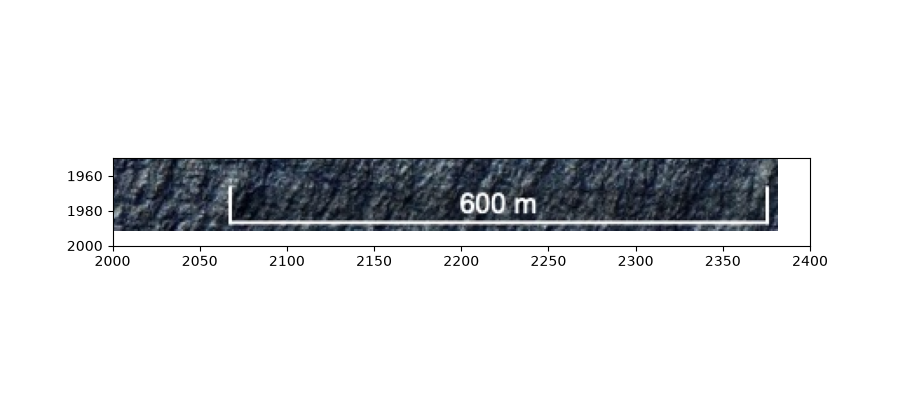

In [86]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(wl)
ax.set_xlim(2000,2400)
ax.set_ylim(2000, 1950)
plt.show()

In [110]:
# for the full path
here = pathlib.Path.cwd()
# or for shorter paths
here = pathlib.Path('.')

dpath_2017 = here / 'sentinel-data/S2_2017-07-12/'
dpath_2018 = here / 'sentinel-data/S2_2018-07-12/'
dpath_2019 = here / 'sentinel-data/S2_2019-07-12/'



# or do it all at once
files_2017 = list((here / 'sentinel-data/S2_2017-07-12').rglob('*.tiff'))
files_2018 = list((here / 'sentinel-data/S2_2018-07-12').rglob('*.tiff'))
files_2019 = list((here / 'sentinel-data/S2_2019-07-12').rglob('*.tiff'))
for i, file in enumerate(files_2017):
    print(i, file)


[WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B01_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B02_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B03_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B04_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B05_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B06_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B07_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B08_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B09_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B11_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B12_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B8A_Raw.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Sentinel-2_L2A_False_color.tiff'),
 WindowsPath('sentinel-data/S2_2017-07-12/Senti

In [109]:
with rasterio.open(files_2017[17]) as arc1:
    f = arc1.read()
with rasterio.open(files_2017[7]) as arc2:
    B8 = arc2.read()
    #profile = arc2.profile
with rasterio.open(files_2017[3]) as arc3:
    B4 = arc3.read(1).astype(np.float32)

# Prevent division by zero using np.errstate or np.where
denominator = B8 + B4

# Ignore warnings temporarily for 0/0 calculations
with np.errstate(divide="ignore", invalid="ignore"):
    vegetation17 = (B8 - B4) / denominator
    # Replace any resulting NaN or infinite values (from 0 / 0) with 0 or np.nan
    vegetation17 = np.nan_to_num(vegetation17, nan=0.0, posinf=0.0, neginf=0.0)
f

array([[[0.75, 0.75, 0.75, ..., 1.  , 1.  , 1.  ],
        [0.75, 0.75, 0.93, ..., 1.  , 1.  , 1.  ],
        [0.75, 0.86, 0.75, ..., 1.  , 1.  , 1.  ],
        ...,
        [1.  , 1.  , 1.  , ..., 0.75, 0.86, 0.75],
        [1.  , 1.  , 1.  , ..., 0.75, 0.75, 0.86],
        [1.  , 1.  , 1.  , ..., 0.75, 0.75, 0.75]],

       [[0.75, 0.75, 0.75, ..., 0.98, 0.98, 0.98],
        [0.75, 0.75, 0.91, ..., 0.98, 0.98, 0.98],
        [0.75, 0.86, 0.75, ..., 0.98, 0.98, 0.98],
        ...,
        [0.98, 0.98, 0.98, ..., 0.75, 0.86, 0.75],
        [0.98, 0.98, 0.98, ..., 0.75, 0.75, 0.86],
        [0.98, 0.98, 0.98, ..., 0.75, 0.75, 0.75]],

       [[0.75, 0.75, 0.75, ..., 0.8 , 0.8 , 0.8 ],
        [0.75, 0.75, 0.71, ..., 0.8 , 0.8 , 0.8 ],
        [0.75, 0.86, 0.75, ..., 0.8 , 0.8 , 0.8 ],
        ...,
        [0.8 , 0.8 , 0.8 , ..., 0.75, 0.86, 0.75],
        [0.8 , 0.8 , 0.8 , ..., 0.75, 0.75, 0.86],
        [0.8 , 0.8 , 0.8 , ..., 0.75, 0.75, 0.75]]],
      shape=(3, 314, 529), dtype=floa

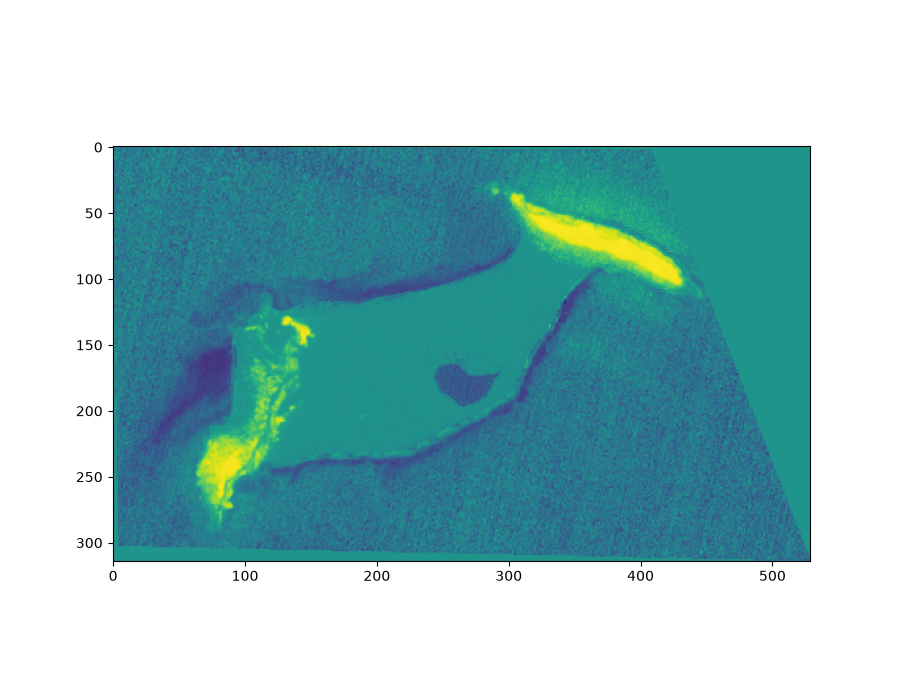

In [64]:
plt.close('all')
rgb_raw = np.stack(( vegetation17))
fog,ax = plt.subplots(figsize=(9,7))

show(rgb_raw, ax=ax)

plt.show()

In [65]:
with rasterio.open(files_2018[7]) as arc2:
    B8 = arc2.read()
    #profile = arc2.profile
with rasterio.open(files_2018[3]) as arc3:
    B4 = arc3.read(1).astype(np.float32)

# Prevent division by zero using np.errstate or np.where
denominator = B8 + B4

# Ignore warnings temporarily for 0/0 calculations
with np.errstate(divide="ignore", invalid="ignore"):
    vegetation18 = (B8 - B4) / denominator
    # Replace any resulting NaN or infinite values (from 0 / 0) with 0 or np.nan
    vegetation18 = np.nan_to_num(vegetation18, nan=0.0, posinf=0.0, neginf=0.0)

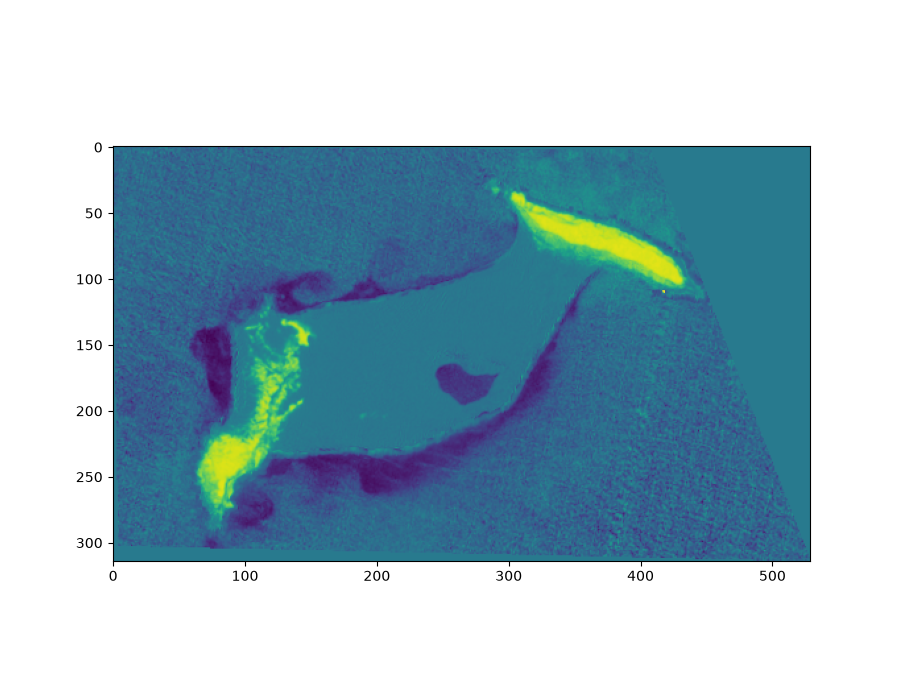

In [66]:
plt.close('all')
rgb_raw = np.stack(( vegetation18))
fog,ax = plt.subplots(figsize=(9,7))

show(rgb_raw, ax=ax)

plt.show()

In [67]:
vegetation18

array([[[-0.0888889 , -0.07142857, -0.14102565, ...,  0.        ,
          0.        ,  0.        ],
        [-0.04918034, -0.03896106, -0.07096774, ...,  0.        ,
          0.        ,  0.        ],
        [-0.01980199, -0.02352943, -0.05142859, ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [ 0.        ,  0.        ,  0.        , ..., -0.3015873 ,
         -0.13821141, -0.11450384],
        [ 0.        ,  0.        ,  0.        , ..., -0.09375001,
         -0.08148148, -0.07042255],
        [ 0.        ,  0.        ,  0.        , ..., -0.12258065,
         -0.02068965, -0.03797468]]], shape=(1, 314, 529), dtype=float32)

In [68]:
with rasterio.open(files_2019[7]) as arc8:
    B8 = arc8.read()
    resolution8 = arc8.res
    bounds8 = arc8.bounds
    #profile = arc2.profile
with rasterio.open(files_2019[3]) as arc4:
    B4 = arc4.read(1).astype(np.float32)
    resolution4 = arc4.res
    bounds4 = arc4.bounds

# Prevent division by zero using np.errstate or np.where
denominator = B8 + B4

# Ignore warnings temporarily for 0/0 calculations
with np.errstate(divide="ignore", invalid="ignore"):
    vegetation19 = (B8 - B4) / denominator
    # Replace any resulting NaN or infinite values (from 0 / 0) with 0 or np.nan
    vegetation19 = np.nan_to_num(vegetation19, nan=0.0, posinf=0.0, neginf=0.0)

In [105]:
with rasterio.open(files_2017[7]) as src:
    # 1. Extract angular pixel resolution (in degrees per pixel)
    res_x, res_y = src.res  
    
    # 2. Extract image bounding box coordinates
    left, bottom, right, top = src.bounds
    
    # 3. Calculate center latitude in radians
    center_lat_deg = (bottom + top) / 2.0
    center_lat_rad = np.radians(center_lat_deg)
meters_per_deg_lat = 111320.0
meters_per_deg_lon = 111320.0 * np.cos(center_lat_rad)
pixel_width_m = res_x * meters_per_deg_lon
pixel_height_m = res_y * meters_per_deg_lat
single_pixel_area_m2 = pixel_width_m * pixel_height_m 

mask = vegetation17>=0.45
vegetation_pixel_count = np.sum(mask)
total_vegetation_area_m217 = vegetation_pixel_count * single_pixel_area_m2
total_vegetation_area_m217
vegetation17


array([[[-0.43661973, -0.37837836, -0.16883115, ...,  0.        ,
          0.        ,  0.        ],
        [-0.42105263, -0.27272722, -0.05882354, ...,  0.        ,
          0.        ,  0.        ],
        [-0.2658228 , -0.23943661, -0.2238806 , ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [ 0.        ,  0.        ,  0.        , ..., -0.27710843,
         -0.15492958, -0.4054054 ],
        [ 0.        ,  0.        ,  0.        , ..., -0.45161292,
         -0.30434778, -0.2280702 ],
        [ 0.        ,  0.        ,  0.        , ..., -0.4098361 ,
         -0.3947368 , -0.32307693]]], shape=(1, 314, 529), dtype=float32)

In [70]:
with rasterio.open(files_2018[7]) as src:
    # 1. Extract angular pixel resolution (in degrees per pixel)
    res_x, res_y = src.res  
    
    # 2. Extract image bounding box coordinates
    left, bottom, right, top = src.bounds
    
    # 3. Calculate center latitude in radians
    center_lat_deg = (bottom + top) / 2.0
    center_lat_rad = np.radians(center_lat_deg)
meters_per_deg_lat = 111320.0
meters_per_deg_lon = 111320.0 * np.cos(center_lat_rad)
pixel_width_m = res_x * meters_per_deg_lon
pixel_height_m = res_y * meters_per_deg_lat
single_pixel_area_m2 = pixel_width_m * pixel_height_m

mask = vegetation18>=0.45
vegetation_pixel_count = np.sum(mask)
total_vegetation_area_m218 = vegetation_pixel_count * single_pixel_area_m2
total_vegetation_area_m218
print(pixel_width_m)
print(pixel_height_m)

9.369821604139815
9.365060891718876


In [71]:
with rasterio.open(files_2019[7]) as src:
    # 1. Extract angular pixel resolution (in degrees per pixel)
    res_x, res_y = src.res  
    
    # 2. Extract image bounding box coordinates
    left, bottom, right, top = src.bounds
    
    # 3. Calculate center latitude in radians
    center_lat_deg = (bottom + top) / 2.0
    center_lat_rad = np.radians(center_lat_deg)
meters_per_deg_lat = 111320.0
meters_per_deg_lon = 111320.0 * np.cos(center_lat_rad)
pixel_width_m = res_x * meters_per_deg_lon
pixel_height_m = res_y * meters_per_deg_lat
single_pixel_area_m2 = pixel_width_m * pixel_height_m

mask = vegetation19>=0.45
vegetation_pixel_count = np.sum(mask)
total_vegetation_area_m219 = vegetation_pixel_count * single_pixel_area_m2
print(pixel_width_m)
print(pixel_height_m)

9.369821604139815
9.365060891718876


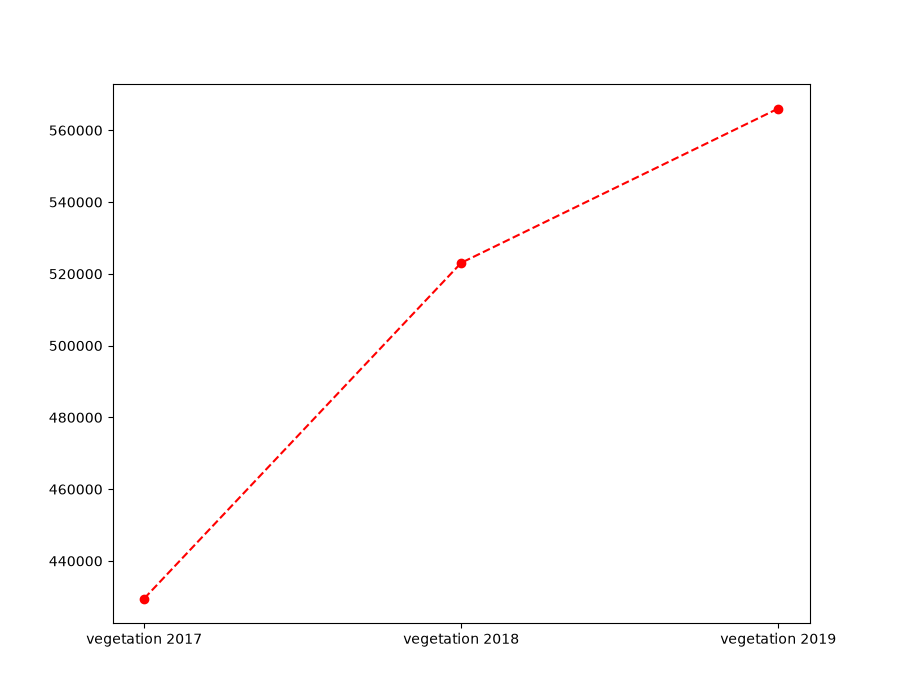

In [102]:
fig,ax = plt.subplots(figsize=(9,7))
xpoints = np.array(["vegetation 2017", "vegetation 2018", "vegetation 2019"])
ypoints = np.array([total_vegetation_area_m217, total_vegetation_area_m218, total_vegetation_area_m219])

plt.scatter(xpoints, ypoints, color = 'red')
plt.plot(xpoints, ypoints, color= 'red', linestyle='--')
plt.show()

<Axes: >

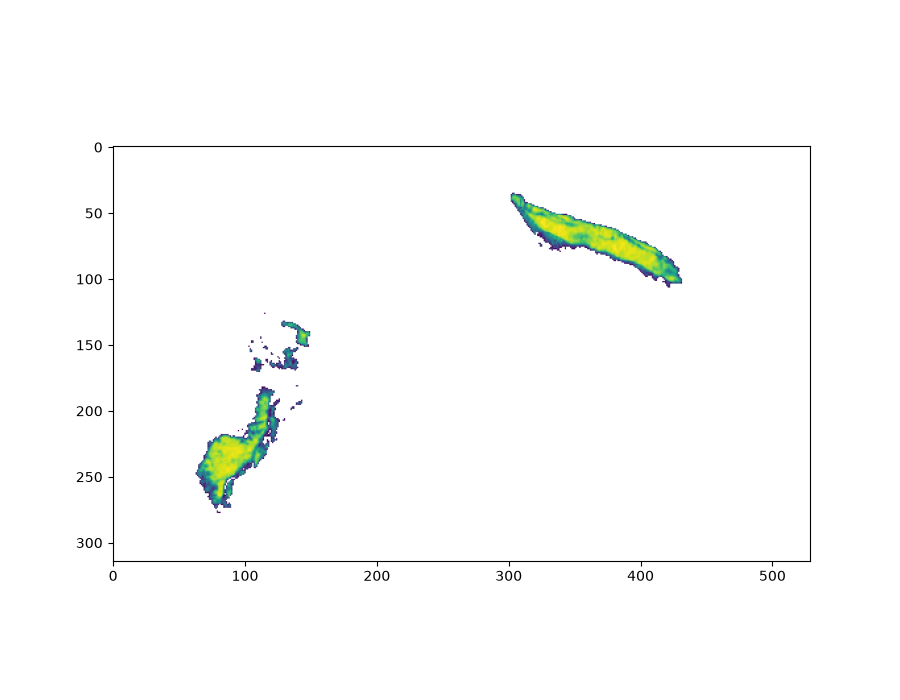

In [101]:
plt.close('all')

fog,ax = plt.subplots(figsize=(9,7))
mask = vegetation19 <(1-0.45)
vegetation_masked = np.ma.masked_array(vegetation19, mask=mask)
show(vegetation_masked, ax=ax)

#plt.show()



In [74]:
white_images = sorted(list((here / 'sentinel-data/White_light').glob('*.jpg')))
for im in white_images:
    print(im)

sentinel-data\White_light\2014Feb.jpg
sentinel-data\White_light\2016May.jpg
sentinel-data\White_light\2020Nov.jpg
sentinel-data\White_light\2021Dec.jpg
sentinel-data\White_light\2022Jan.jpg
sentinel-data\White_light\2023Oct.jpg


In [75]:
white_images

[WindowsPath('sentinel-data/White_light/2014Feb.jpg'),
 WindowsPath('sentinel-data/White_light/2016May.jpg'),
 WindowsPath('sentinel-data/White_light/2020Nov.jpg'),
 WindowsPath('sentinel-data/White_light/2021Dec.jpg'),
 WindowsPath('sentinel-data/White_light/2022Jan.jpg'),
 WindowsPath('sentinel-data/White_light/2023Oct.jpg')]

In [91]:
#import cv2
import numpy as np

# 1. Load the image
image_path = 'sentinel-data\White_light\2014Feb.jpg'

img = mpimg.imread(image_path)

# 2. Define the known scale bar parameters from the image
# The scale bar represents 600 meters.
real_world_length_meters = 600.0

# Based on the plot's X-axis coordinates:
# The scale bar starts at roughly x = 2067 and ends at x = 2377
scale_bar_start_x = 2067
scale_bar_end_x = 2377

scale_bar_units = scale_bar_end_x - scale_bar_start_x

# Calculate the conversion factor (meters per axis unit)
meters_per_unit = real_world_length_meters / scale_bar_units

# 3. Define the region of interest (ROI) coordinates from the axes
# For example, the full bounding box shown in the plot:
# X ranges from 2000 to 2400
# Y ranges from 1960 to 2000
x_min, x_max = 2000, 2400
y_min, y_max = 1960, 2000

width_units = x_max - x_min
height_units = y_max - y_min

# 4. Convert dimensions to meters
width_meters = width_units * meters_per_unit
height_meters = height_units * meters_per_unit  # Assumes square/isotropic pixels

# 5. Calculate Area
area_sq_meters = width_meters * height_meters

FileNotFoundError: [Errno 2] No such file or directory: 'sentinel-data\\White_light\x814Feb.jpg'

0.213946
3.600416
2.225386
11.825205
0.726056
1.435542


1.9169329073482428

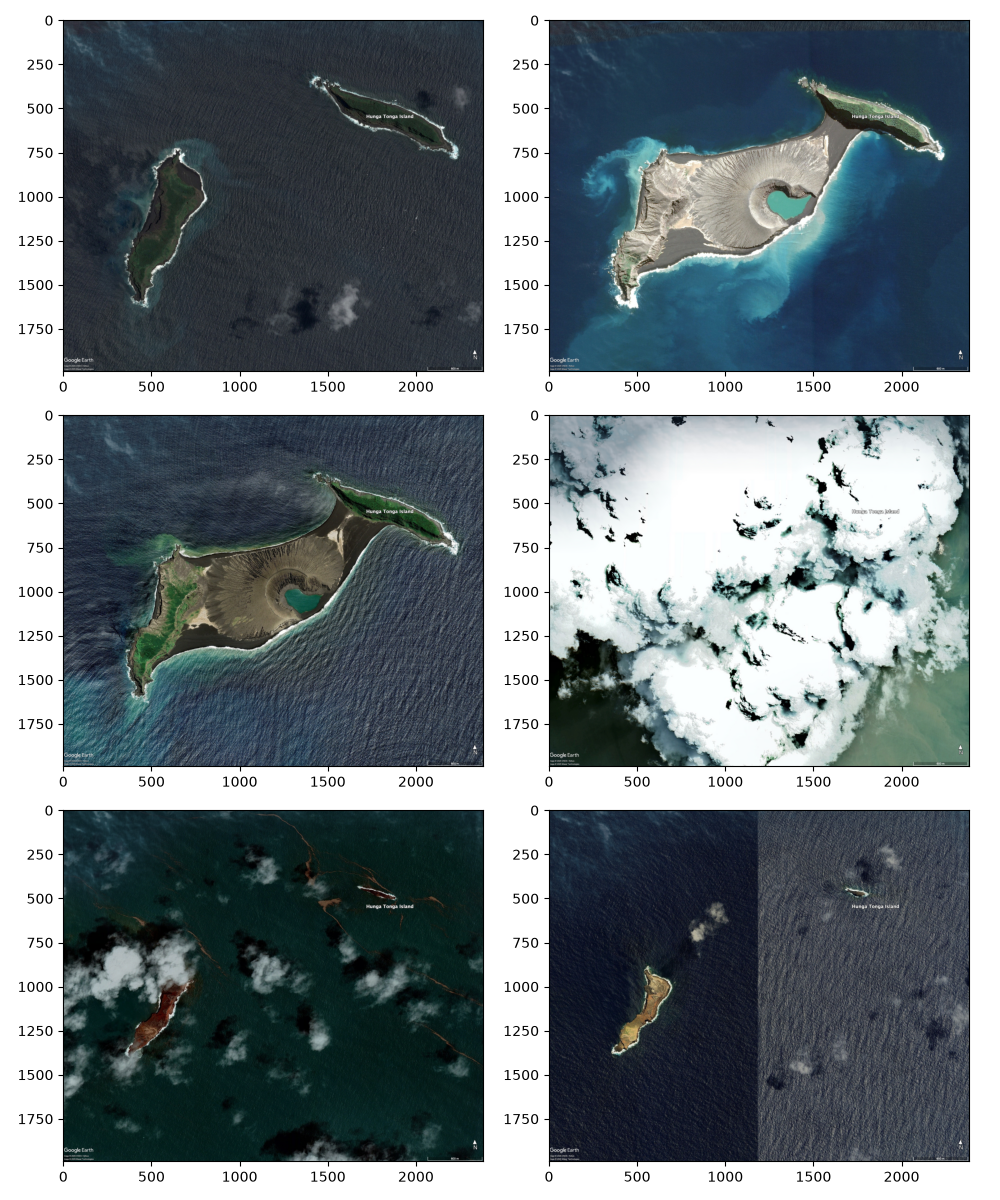

In [98]:
plt.close('all')
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), tight_layout=True)
axes = axes.ravel()
land_area = {}
for i, ax in enumerate(axes):
    img = mpimg.imread(white_images[i])
    ax.imshow(img)
    img_array = np.array(img)
#mask = img_array < (128)

#fig,ax = plt.subplots(figsize=(9,7))
#land_mask = np.ma.masked_array(img_array, mask=mask)
    land_pixel_count = np.count_nonzero(img_array > 100)
    
#ax.imshow(wl)
#plt.show
    print(land_pixel_count/1000000)
real_world_length_meters = 600.0
scale_bar_start_x = 2062   # Example pixel coordinate for left tick
scale_bar_end_x = 2375
scale_bar_pixels = scale_bar_end_x - scale_bar_start_x
meters_per_pixel = real_world_length_meters / scale_bar_pixels
meters_per_pixel

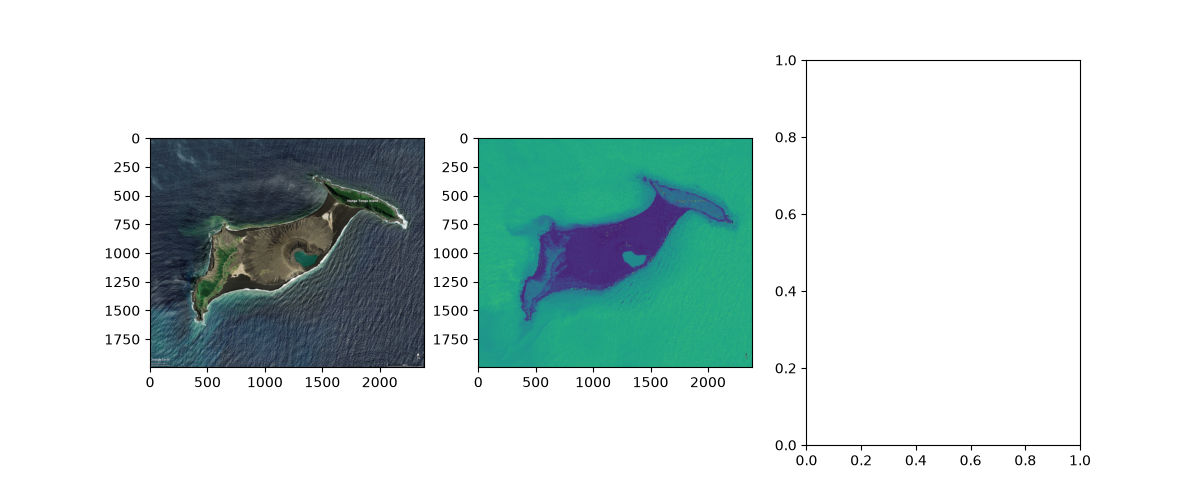

3666747


In [99]:
from matplotlib.colors import rgb_to_hsv

rgb_image = mpimg.imread(white_images[2])
plt.close('all')
fig, ax = plt.subplots(figsize=(9, 9))
hist2d_redvblue, *_ = np.histogram2d(
    rgb_image[:, :, 0].flatten(),
    rgb_image[:, :, 2].flatten(),
    bins=np.arange(0, 255)
)

red_hist = np.histogram(rgb_image[:, :, 0], bins=np.arange(0, 255))
green_hist = np.histogram(rgb_image[:, :, 1], bins=np.arange(0, 255))
blue_hist = np.histogram(rgb_image[:, :, 2], bins=np.arange(0, 255))

plt.close('all')
rgb_norm = rgb_image / 255
hsv_image = rgb_to_hsv(rgb_norm)

fig, (ax1, ax2,ax3) = plt.subplots(ncols=3, figsize=(12, 5))
ax1.imshow(rgb_image)
ax2.imshow(hsv_image[:, :, 0])
plt.show()
img_array2 = np.array(hsv_image[:, :, 0])
#mask = img_array < (128)

#fig,ax = plt.subplots(figsize=(9,7))
#land_mask = np.ma.masked_array(img_array, mask=mask)
#land_pixel_count = np.count_nonzero(img_array2 > 0.1)

mask = img_array2 > 0.5
lande_masked = np.ma.masked_array(img_array2, mask=mask)
ax3.imshow(lande_masked)
g = np.sum(mask)
print(g)
#ax.imshow(wl)
#plt.show
#ax3.imshow(img_array2)

In [78]:
plt.close('all')
pixels_in_scale = 600/pixel_width_m
pixel_area = pixel_height_m*pixel_width_m
wl = mpimg.imread('sentinel-data/White_light/2020Nov.jpg')
img_array = np.array(wl)
#mask = img_array < (128)

#fig,ax = plt.subplots(figsize=(9,7))
#land_mask = np.ma.masked_array(img_array, mask=mask)
land_pixel_count = np.count_nonzero(img_array > 128)

#ax.imshow(wl)
#plt.show
land_pixel_count


np.int64(750120)

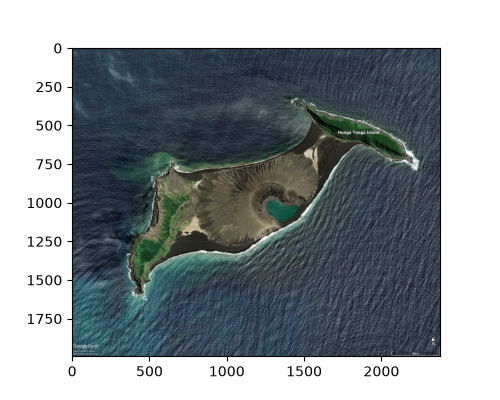

In [79]:
plt.close('all')



show(vegetation_masked, ax=ax)
#mpimg.imread(path+'/White_light/2020Nov.jpg')

wl = mpimg.imread('sentinel-data/White_light/2020Nov.jpg')
fig,ax = plt.subplots(figsize=(5,4))
mask = wl >(255)
vegetation_masked = np.ma.masked_array(wl, mask=mask)
ax.imshow(vegetation_masked)
#ax.set_xlim(1500,2400)
#ax.set_ylim(2000,1750)
plt.show()